In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

import torch
import torch.nn as nn
torch.manual_seed(42)
import torch.optim as optim
from torchinfo import summary
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models, datasets

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
train_path = "dataset/train"
test_path = "dataset/test"
df= pd.read_csv("dataset/train.csv")
train_idx , val_idx = train_test_split(range(len(df)), test_size=0.2, random_state=42, stratify=df["Class"])
df.head()

,Image,Class
0,image3476.jpg,Miscellaneous
1,image5198.jpg,Candle
2,image4183.jpg,Snowman
3,image1806.jpg,Miscellaneous
4,image7831.jpg,Miscellaneous


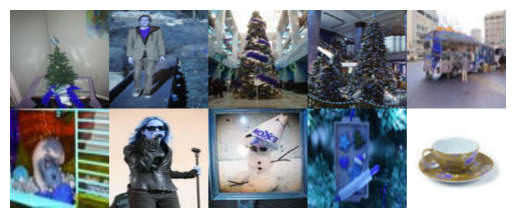

In [4]:
import cv2
import os
import matplotlib.pyplot as plt

lt= []

for image in os.listdir(train_path):
    img_path = os.path.join(train_path, image)
    img = cv2.imread(img_path)
    lt.append(cv2.resize(img, (150, 150)))
    if len(lt) == 10 :
        break
row1 = cv2.hconcat(lt[:5])
row2 = cv2.hconcat(lt[5:10])
stacked = cv2.vconcat([row1,row2])
plt.imshow(stacked)
plt.axis("off")
plt.show()

In [5]:
import pandas as pd
print(df["Class"].value_counts())

Class
Miscellaneous     2801
Christmas_Tree    1539
Jacket             640
Candle             593
Airplane           535
Snowman            361
Name: count, dtype: int64


In [6]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

In [7]:
print(df["Class"].unique())
print(df.shape[0])

['Miscellaneous' 'Candle' 'Snowman' 'Airplane' 'Christmas_Tree' 'Jacket']
6469


In [8]:

from PIL import Image
class CustomDataset(Dataset):
    def __init__(self, csv_file, image_dir, transform = None):
        self.csv_file = csv_file
        self.image_dir = image_dir
        self.transform = transform
        self.df = pd.read_csv(csv_file)

        self.classes = sorted(self.df["Class"].unique())
        self.class_idx = {cls: idx for idx, cls in enumerate(self.classes) }
    def __len__(self):
        return self.csv.file.shape[0]
    def __getitem__(self, idx):
        image_name = self.df["Image"].iloc[idx]
        label = self.class_idx[self.df["Class"].iloc[idx]]

        image_path = os.path.join(self.image_dir, image_name)
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)
        return image , label

In [9]:
from torch.utils.data import Subset

train_full = CustomDataset(
    "dataset/train.csv",
    train_path,
    train_transform
)
val_full = CustomDataset(
    "dataset/train.csv",
    train_path,
    test_transform
)
train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [11]:
images,  labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

torch.Size([32, 3, 128, 128])
torch.Size([32])


In [64]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size =3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64,128, kernel_size =3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(128,256, kernel_size =3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(256,256, kernel_size =3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(256,256, kernel_size =3, padding= 1),
            nn.ReLU(),
            #nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(16384,128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 6)
        )
    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x) 
        return x

In [65]:
model = CNN()
print(model)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_layers): Sequential(
    (0): Linear(in_features=16384, out_features=128, bias=True)
    (1): ReLU()
    (2): Dr

In [66]:
summary(model)

Layer (type:depth-idx)                   Param #
CNN                                      --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       1,792
│    └─ReLU: 2-2                         --
│    └─MaxPool2d: 2-3                    --
│    └─Conv2d: 2-4                       73,856
│    └─ReLU: 2-5                         --
│    └─MaxPool2d: 2-6                    --
│    └─Conv2d: 2-7                       295,168
│    └─ReLU: 2-8                         --
│    └─MaxPool2d: 2-9                    --
│    └─Conv2d: 2-10                      590,080
│    └─ReLU: 2-11                        --
│    └─MaxPool2d: 2-12                   --
│    └─Conv2d: 2-13                      590,080
│    └─ReLU: 2-14                        --
│    └─Flatten: 2-15                     --
├─Sequential: 1-2                        --
│    └─Linear: 2-16                      2,097,280
│    └─ReLU: 2-17                        --
│    └─Dropout: 2-18                     -

In [67]:
model = model.to(device)

In [68]:
# verify forward pass
images = images.to(device)
output = model(images)
output.shape

torch.Size([32, 6])

In [69]:
from sklearn.utils.class_weight import compute_class_weight

classes = train_full.classes

weights = compute_class_weight(
    class_weight = "balanced",
    classes = np.arange(len(classes)),
    y = train_full.df["Class"].map(train_full.class_idx).iloc[train_idx].values
)
class_weights = torch.tensor(weights, dtype = torch.float32).to(device)

In [70]:
criterion = nn.CrossEntropyLoss(weight = class_weights)

optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001,
    weight_decay=1e-4
)

In [71]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# Training and Validation with Early Stopping
# with learning-rate scheduler
# Saving the Best model


In [74]:
epochs = 100

best_val_loss = float("inf")
patience = 5
counter = 0

train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []


for i in range(epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()* images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total
    
    #-------------------------------------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()* images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0) 

        val_loss = val_running_loss / val_total
        val_acc = 100 * val_correct / val_total

    scheduler.step(val_loss) # learning-rate scheduler
    
    # Store metrics
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
        
    print(
        f"Epoch [{i+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )
    
    # ----------------- early stoping -------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        
        torch.save(model.state_dict(), "best_model.pth")

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(
    torch.load("best_model.pth", map_location=device, weights_only=True)
)

Epoch [1/100] | Train Loss: 1.3040 | Val Loss: 1.4025 | Train Acc: 36.21% | Val Acc: 35.55%
Epoch [2/100] | Train Loss: 1.2661 | Val Loss: 1.3334 | Train Acc: 37.72% | Val Acc: 32.69%
Epoch [3/100] | Train Loss: 1.2624 | Val Loss: 1.3213 | Train Acc: 39.29% | Val Acc: 39.03%
Epoch [4/100] | Train Loss: 1.1917 | Val Loss: 1.2999 | Train Acc: 41.51% | Val Acc: 42.27%
Epoch [5/100] | Train Loss: 1.1827 | Val Loss: 1.3809 | Train Acc: 42.98% | Val Acc: 39.03%
Epoch [6/100] | Train Loss: 1.1703 | Val Loss: 1.2991 | Train Acc: 43.54% | Val Acc: 35.94%
Epoch [7/100] | Train Loss: 1.1451 | Val Loss: 1.2694 | Train Acc: 45.55% | Val Acc: 42.19%
Epoch [8/100] | Train Loss: 1.1187 | Val Loss: 1.2751 | Train Acc: 46.22% | Val Acc: 42.74%
Epoch [9/100] | Train Loss: 1.1285 | Val Loss: 1.2830 | Train Acc: 45.14% | Val Acc: 41.58%
Epoch [10/100] | Train Loss: 1.1027 | Val Loss: 1.2438 | Train Acc: 47.86% | Val Acc: 44.59%
Epoch [11/100] | Train Loss: 1.0951 | Val Loss: 1.2432 | Train Acc: 47.15% | Va

<All keys matched successfully>

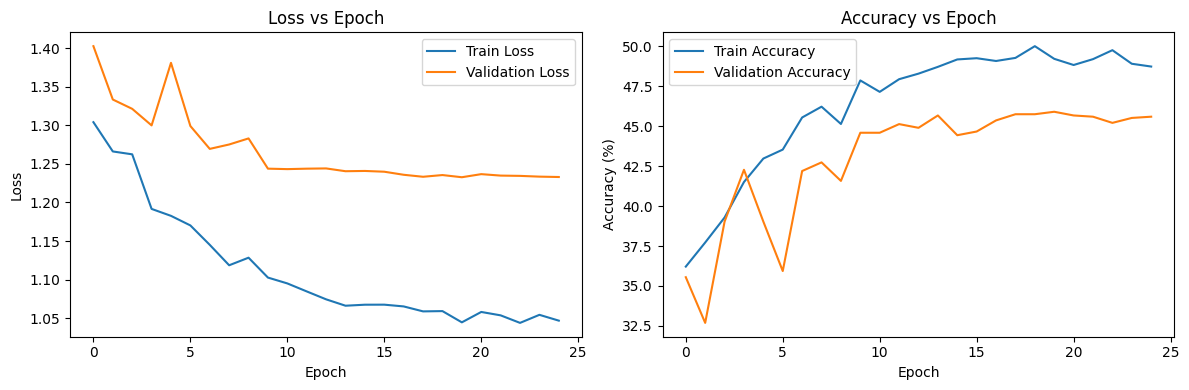

In [77]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_loss_list, label="Train Loss")
plt.plot(val_loss_list, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_acc_list, label="Train Accuracy")
plt.plot(val_acc_list, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs Epoch")
plt.legend()

plt.tight_layout()
plt.show()

# just directly training without anything

epochs = 100

for i in range(epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        output = model(images)

        loss = criterion(
            output,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        
    print(f"Epoch [{i+1}/{epochs}]  Loss : {running_loss:.4f}")

# evaluation 
def calculate_accuracy(model, dataloader, device):
    model.eval()
    total = 0
    correct = 0
    
    with torch.no_grad():
    
      for batch_features, batch_labels in dataloader:
    
        # move data to gpu
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
    
        outputs = model(batch_features)
    
        _, predicted = torch.max(outputs, 1)
    
        total = total + batch_labels.shape[0]
    
        correct = correct + (predicted == batch_labels).sum().item()
    
    return 100* correct/total

train_acc_list = []
val_acc_list = []
print("Accuracy\n")
epochs = 10
for i in range(epochs):
    model.train()
    train_acc = calculate_accuracy(model, train_loader, device)
    val_acc = calculate_accuracy(model, val_loader, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    print(f"Epoch [{i+1}/{epochs}]  Train Accuracy : {train_acc:.2f}  Val Accuracy : {val_acc:.2f}")
    

In [78]:
model.eval()

images, labels = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

    predictions = torch.argmax(outputs, dim = 1)
images = images.cpu()

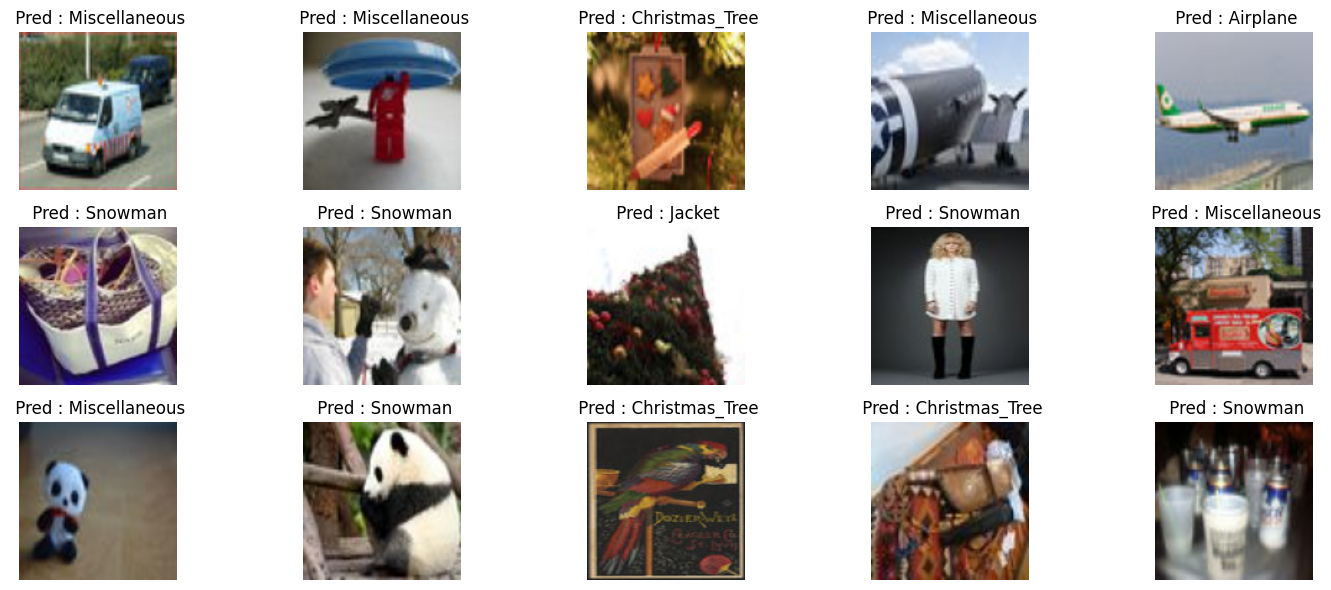

In [79]:
fig, axes = plt.subplots(3,5, figsize=(15,6))

classes = train_full.classes

for i, ax in enumerate(axes.flatten()):
    img = images[i].permute(1,2,0)
    ax.imshow(img)
    pred_label = classes[predictions[i]]
    ax.set_title(f" Pred : {pred_label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [80]:
from sklearn.metrics import confusion_matrix

y_true =[]
y_pred = []
model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        pred = torch.argmax(outputs, dim = 1)
        y_true.extend(labels.numpy())
        y_pred.extend(pred.cpu().numpy())

cm = confusion_matrix(y_true,y_pred)
print("confusion matrix\n",cm)


from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names = train_full.classes))

confusion matrix
 [[ 75   1   3   4  15   9]
 [  5  67  19   4  11  13]
 [  5  32 163  53  35  20]
 [  1   2  23  76  16  10]
 [114  61  44  63 174 104]
 [  7   4   3  10   9  39]]
                precision    recall  f1-score   support

      Airplane       0.36      0.70      0.48       107
        Candle       0.40      0.56      0.47       119
Christmas_Tree       0.64      0.53      0.58       308
        Jacket       0.36      0.59      0.45       128
 Miscellaneous       0.67      0.31      0.42       560
       Snowman       0.20      0.54      0.29        72

      accuracy                           0.46      1294
     macro avg       0.44      0.54      0.45      1294
  weighted avg       0.56      0.46      0.46      1294



# DenseNet Architecture 

In [109]:
class denselayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super().__init__()
        self.layer = nn.Sequential(
            nn.BatchNorm2d(in_channels),
            nn.ReLU(),
            nn.Conv2d(in_channels, growth_rate, kernel_size=3, padding=1, bias=False)
        )
    def forward(self, x):
        new_features = self.layer(x)
        return torch.cat([x, new_features], dim = 1)

class denseblock(nn.Module):
    def __init__(self, in_channels, num_layers, growth_rate):
        super().__init__()
        
        self.layers = nn.ModuleList()

        for i in range(num_layers):
            layer = denselayer(in_channels + i *growth_rate, growth_rate)
            self.layers.append(layer)

    def forward(self,x):
        for layer in self.layers:
            x = layer(x)
        return x

class transitionlayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layer = nn.Sequential(
            nn.BatchNorm2d(in_channels),
            nn.ReLU(),
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )
    def forward(self, x):
        return self.layer(x)

class densenet(nn.Module):
    def __init__(self, num_classes = 6, growth_rate = 32, block_layers = (3,3,3)):
        super().__init__()

        channels = 32

        self.stem = nn.Sequential(
            nn.Conv2d( 3, channels, kernel_size=3, stride=1, padding=1, bias=False ),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

        self.block1 = denseblock(channels, block_layers[0], growth_rate )

        channels += block_layers[0] * growth_rate
        out_channels = channels // 2

        self.trans1 = transitionlayer(channels, out_channels)

        channels = out_channels

        self.block2 = denseblock(channels, block_layers[1], growth_rate )

        channels += block_layers[1] * growth_rate
        out_channels = channels // 2

        self.trans2 = transitionlayer(channels, out_channels)

        channels = out_channels

        self.block3 = denseblock(channels, block_layers[2], growth_rate )

        channels += block_layers[2] * growth_rate
        
        self.final_layers = nn.Sequential(
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.trans1(x)
        x = self.block2(x)
        x = self.trans2(x)
        x = self.block3(x)
        return self.final_layers(x)
        

In [110]:
model = densenet(num_classes=6).to(device)

images = torch.randn(2, 3, 128, 128).to(device)
outputs = model(images)

print(outputs.shape)

torch.Size([2, 6])


In [111]:
model = densenet( num_classes = 6, growth_rate = 32, block_layers = (3,3,3)).to(device)
summary(model)

Layer (type:depth-idx)                        Param #
densenet                                      --
├─Sequential: 1-1                             --
│    └─Conv2d: 2-1                            864
│    └─BatchNorm2d: 2-2                       64
│    └─ReLU: 2-3                              --
├─denseblock: 1-2                             --
│    └─ModuleList: 2-4                        --
│    │    └─denselayer: 3-1                   9,280
│    │    └─denselayer: 3-2                   18,560
│    │    └─denselayer: 3-3                   27,840
├─transitionlayer: 1-3                        --
│    └─Sequential: 2-5                        --
│    │    └─BatchNorm2d: 3-4                  256
│    │    └─ReLU: 3-5                         --
│    │    └─Conv2d: 3-6                       8,192
│    │    └─AvgPool2d: 3-7                    --
├─denseblock: 1-4                             --
│    └─ModuleList: 2-6                        --
│    │    └─denselayer: 3-8                   18

In [112]:
from sklearn.utils.class_weight import compute_class_weight

classes = train_full.classes

weights = compute_class_weight(
    class_weight = "balanced",
    classes = np.arange(len(classes)),
    y = train_full.df["Class"].map(train_full.class_idx).iloc[train_idx].values
)
class_weights = torch.tensor(weights, dtype = torch.float32).to(device)
#--------------------------------------------
criterion = nn.CrossEntropyLoss(weight = class_weights)

optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001,
    weight_decay=1e-4
)
#--------------------------------------------
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [113]:
epochs = 100

best_val_loss = float("inf")
patience = 5
counter = 0

train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []


for i in range(epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()* images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total
    
    #-------------------------------------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()* images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0) 

        val_loss = val_running_loss / val_total
        val_acc = 100 * val_correct / val_total

    scheduler.step(val_loss) # learning-rate scheduler
    
    # Store metrics
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
        
    print(
        f"Epoch [{i+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )
    
    # ----------------- early stoping -------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        
        torch.save(model.state_dict(), "best_model.pth")

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(
    torch.load("best_model.pth", map_location=device, weights_only=True)
)

Epoch [1/100] | Train Loss: 1.4385 | Val Loss: 1.4248 | Train Acc: 39.27% | Val Acc: 38.33%
Epoch [2/100] | Train Loss: 1.3295 | Val Loss: 1.3760 | Train Acc: 44.29% | Val Acc: 43.51%
Epoch [3/100] | Train Loss: 1.2636 | Val Loss: 1.2487 | Train Acc: 46.07% | Val Acc: 44.59%
Epoch [4/100] | Train Loss: 1.2328 | Val Loss: 1.3399 | Train Acc: 47.13% | Val Acc: 38.49%
Epoch [5/100] | Train Loss: 1.1743 | Val Loss: 2.0007 | Train Acc: 49.14% | Val Acc: 29.06%
Epoch [6/100] | Train Loss: 1.1293 | Val Loss: 1.3485 | Train Acc: 51.46% | Val Acc: 43.20%
Epoch [7/100] | Train Loss: 1.0619 | Val Loss: 1.1546 | Train Acc: 53.41% | Val Acc: 52.47%
Epoch [8/100] | Train Loss: 1.0421 | Val Loss: 1.2472 | Train Acc: 54.71% | Val Acc: 44.90%
Epoch [9/100] | Train Loss: 1.0232 | Val Loss: 1.2456 | Train Acc: 55.48% | Val Acc: 49.92%
Epoch [10/100] | Train Loss: 0.9987 | Val Loss: 1.1317 | Train Acc: 55.13% | Val Acc: 46.06%
Epoch [11/100] | Train Loss: 0.9934 | Val Loss: 1.1449 | Train Acc: 56.43% | Va

<All keys matched successfully>

# Using Pre-trained Model

In [26]:
# model -- resnet50 just changing last classifier layer

In [27]:
model = models.resnet50(weights ="DEFAULT" )

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\abhij/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:21<00:00, 4.72MB/s]


In [29]:
for param in model.parameters():
    param.requires_grad = False
'''
for param in model.classifier.parameters():
    param.requires_grad = True
    '''

'\nfor param in model.classifier.parameters():\n    param.requires_grad = True\n    '

In [30]:
num_classes = len(train_full.classes)
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)
model = model.to(device)

In [35]:
for i ,(name, param ) in enumerate(model.named_parameters(),start=1):
    print(f"{i:3d}.  {name:50s}"
         f"Trainable: {param.requires_grad}")

  1.  conv1.weight                                      Trainable: False
  2.  bn1.weight                                        Trainable: False
  3.  bn1.bias                                          Trainable: False
  4.  layer1.0.conv1.weight                             Trainable: False
  5.  layer1.0.bn1.weight                               Trainable: False
  6.  layer1.0.bn1.bias                                 Trainable: False
  7.  layer1.0.conv2.weight                             Trainable: False
  8.  layer1.0.bn2.weight                               Trainable: False
  9.  layer1.0.bn2.bias                                 Trainable: False
 10.  layer1.0.conv3.weight                             Trainable: False
 11.  layer1.0.bn3.weight                               Trainable: False
 12.  layer1.0.bn3.bias                                 Trainable: False
 13.  layer1.0.downsample.0.weight                      Trainable: False
 14.  layer1.0.downsample.1.weight                 

In [32]:
from sklearn.utils.class_weight import compute_class_weight

classes = train_full.classes

weights = compute_class_weight(
    class_weight = "balanced",
    classes = np.arange(len(classes)),
    y = train_full.df["Class"].map(train_full.class_idx).iloc[train_idx].values
)
class_weights = torch.tensor(weights, dtype = torch.float32).to(device)
#--------------------------------------------
criterion = nn.CrossEntropyLoss(weight = class_weights)

optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [36]:
epochs = 100

best_val_loss = float("inf")
patience = 5
counter = 0

train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []


for i in range(epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()* images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total
    
    #-------------------------------------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()* images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0) 

        val_loss = val_running_loss / val_total
        val_acc = 100 * val_correct / val_total

    
    # Store metrics
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
        
    print(
        f"Epoch [{i+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )
    
    # ----------------- early stoping -------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        
        torch.save(model.state_dict(), "best_model.pth")

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(
    torch.load("best_model.pth", map_location=device, weights_only=True)
)

Epoch [1/100] | Train Loss: 0.7046 | Val Loss: 0.5489 | Train Acc: 71.09% | Val Acc: 79.44%
Epoch [2/100] | Train Loss: 0.5961 | Val Loss: 0.4970 | Train Acc: 75.15% | Val Acc: 80.68%
Epoch [3/100] | Train Loss: 0.5286 | Val Loss: 0.4782 | Train Acc: 77.06% | Val Acc: 83.31%
Epoch [4/100] | Train Loss: 0.4902 | Val Loss: 0.4407 | Train Acc: 78.05% | Val Acc: 84.08%
Epoch [5/100] | Train Loss: 0.4725 | Val Loss: 0.4208 | Train Acc: 79.56% | Val Acc: 84.08%
Epoch [6/100] | Train Loss: 0.4729 | Val Loss: 0.4257 | Train Acc: 79.90% | Val Acc: 84.54%
Epoch [7/100] | Train Loss: 0.4424 | Val Loss: 0.4282 | Train Acc: 80.00% | Val Acc: 85.01%
Epoch [8/100] | Train Loss: 0.4437 | Val Loss: 0.4151 | Train Acc: 80.25% | Val Acc: 84.70%
Epoch [9/100] | Train Loss: 0.4256 | Val Loss: 0.4175 | Train Acc: 81.62% | Val Acc: 83.15%
Epoch [10/100] | Train Loss: 0.4091 | Val Loss: 0.3972 | Train Acc: 80.97% | Val Acc: 83.54%
Epoch [11/100] | Train Loss: 0.3941 | Val Loss: 0.4275 | Train Acc: 81.64% | Va

<All keys matched successfully>

In [42]:
from sklearn.metrics import classification_report

y_true=[]
y_pred=[]
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        pred = torch.argmax(outputs, dim = 1)
        y_true.extend(labels.numpy())
        y_pred.extend(pred.cpu().numpy())

print(classification_report(
    y_true,
    y_pred,
    target_names = train_full.classes
))

                precision    recall  f1-score   support

      Airplane       0.73      0.94      0.82       107
        Candle       0.64      0.94      0.76       119
Christmas_Tree       0.90      0.84      0.87       308
        Jacket       0.87      0.96      0.91       128
 Miscellaneous       0.92      0.78      0.84       560
       Snowman       0.65      0.72      0.68        72

      accuracy                           0.84      1294
     macro avg       0.79      0.86      0.82      1294
  weighted avg       0.85      0.84      0.84      1294



# finetuning with unfreezing layer 4

In [43]:
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

In [44]:
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

In [45]:
from sklearn.utils.class_weight import compute_class_weight

classes = train_full.classes

weights = compute_class_weight(
    class_weight = "balanced",
    classes = np.arange(len(classes)),
    y = train_full.df["Class"].map(train_full.class_idx).iloc[train_idx].values
)
class_weights = torch.tensor(weights, dtype = torch.float32).to(device)
#--------------------------------------------
criterion = nn.CrossEntropyLoss(weight = class_weights)


In [46]:
epochs = 7

best_val_loss = float("inf")
patience = 5
counter = 0

train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []


for i in range(epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()* images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total
    
    #-------------------------------------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()* images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0) 

        val_loss = val_running_loss / val_total
        val_acc = 100 * val_correct / val_total

    
    # Store metrics
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
        
    print(
        f"Epoch [{i+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )
    
    # ----------------- early stoping -------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        
        torch.save(model.state_dict(), "best_model.pth")

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(
    torch.load("best_model.pth", map_location=device, weights_only=True)
)

Epoch [1/7] | Train Loss: 0.4578 | Val Loss: 0.4454 | Train Acc: 80.29% | Val Acc: 86.71%
Epoch [2/7] | Train Loss: 0.2954 | Val Loss: 0.3564 | Train Acc: 86.20% | Val Acc: 86.71%
Epoch [3/7] | Train Loss: 0.2282 | Val Loss: 0.3857 | Train Acc: 89.08% | Val Acc: 86.71%
Epoch [4/7] | Train Loss: 0.2158 | Val Loss: 0.4471 | Train Acc: 89.93% | Val Acc: 87.40%
Epoch [5/7] | Train Loss: 0.1789 | Val Loss: 0.4537 | Train Acc: 92.02% | Val Acc: 87.56%
Epoch [6/7] | Train Loss: 0.1481 | Val Loss: 0.4370 | Train Acc: 92.44% | Val Acc: 89.18%
Epoch [7/7] | Train Loss: 0.1287 | Val Loss: 0.4121 | Train Acc: 93.70% | Val Acc: 87.56%
Early stopping triggered!


<All keys matched successfully>

In [47]:
model.eval()

images, labels = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

    predictions = torch.argmax(outputs, dim = 1)
images = images.cpu()

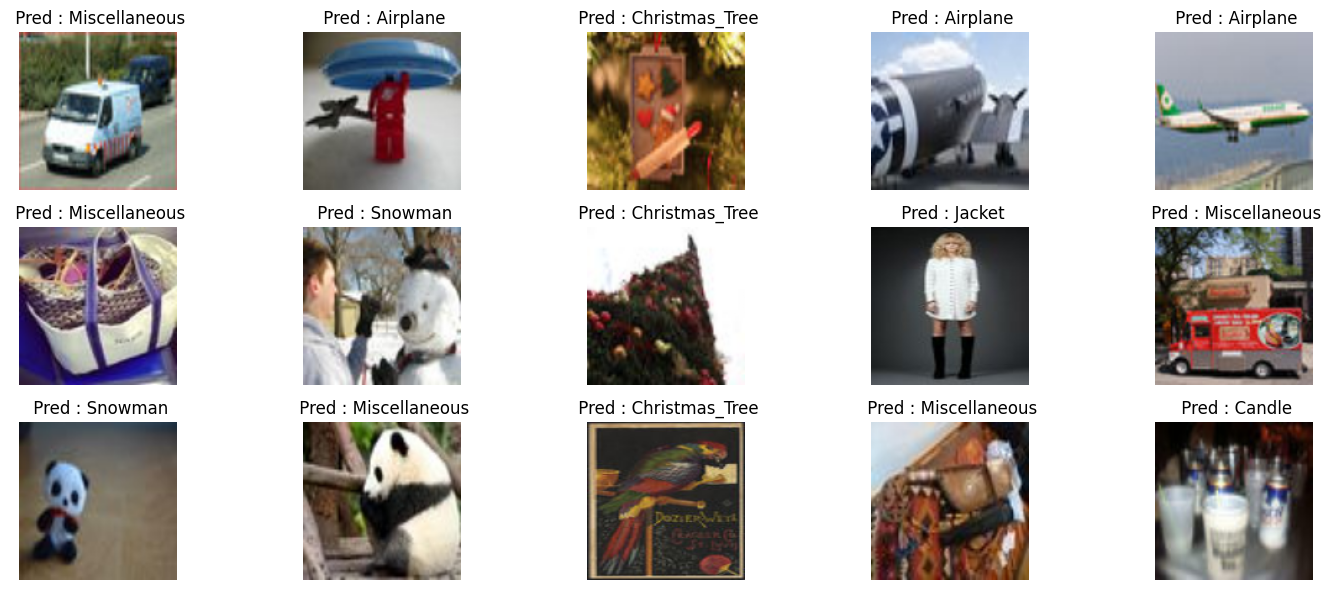

In [48]:
fig, axes = plt.subplots(3,5, figsize=(15,6))

classes = train_full.classes

for i, ax in enumerate(axes.flatten()):
    img = images[i].permute(1,2,0)
    ax.imshow(img)
    pred_label = classes[predictions[i]]
    ax.set_title(f" Pred : {pred_label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

model.eval()
all_preds = []
all_labels = []

class_names = train_full.classes

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=45, cmap="Blues")

plt.tight_layout()
plt.show()

In [12]:
# save class names
classes = train_full.classes

import pickle

with open("classes.pkl", "wb") as f:
    pickle.dump(classes, f)